#**RNN and LSTM on Synthetic Time-Series Data**

   Time     Value
0     0  0.049671
1     1  0.032162
2     2  0.156675
3     3  0.289986
4     4  0.159834
Dataset Shape: (2000, 2)


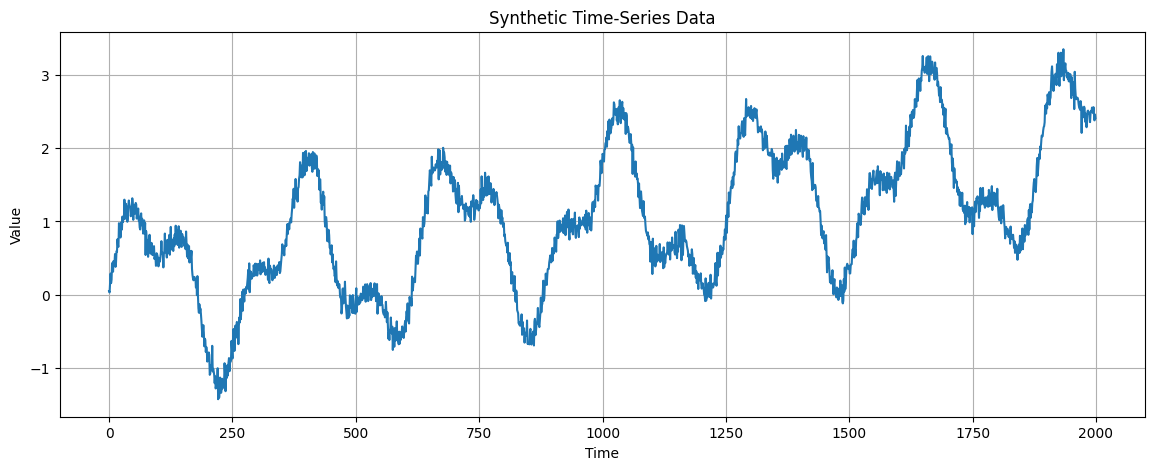

Scaled Data Shape: (2000, 1)
X Train: (1550, 50, 1)
y Train: (1550,)
X Test: (400, 50, 1)
y Test: (400,)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,901 (15.24 KB)

 Trainable params: 3,901 (15.24 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0337 - val_loss: 0.0028
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0079 - val_loss: 0.0024
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0051 - val_loss: 0.0013
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0050 - val_loss: 0.0034
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0040 - val_loss: 0.0023
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0028 - val_loss: 0.0010
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0026 - val_loss: 8.7141e-04
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0029 - val_loss: 0.0014
Epoch 9/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0026 - val_loss: 8.4095e-04
Epoch 10/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0025 - val_loss: 0.0010
Epoch 11/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0027 - val_loss: 0.0020
Epoch 12/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - l

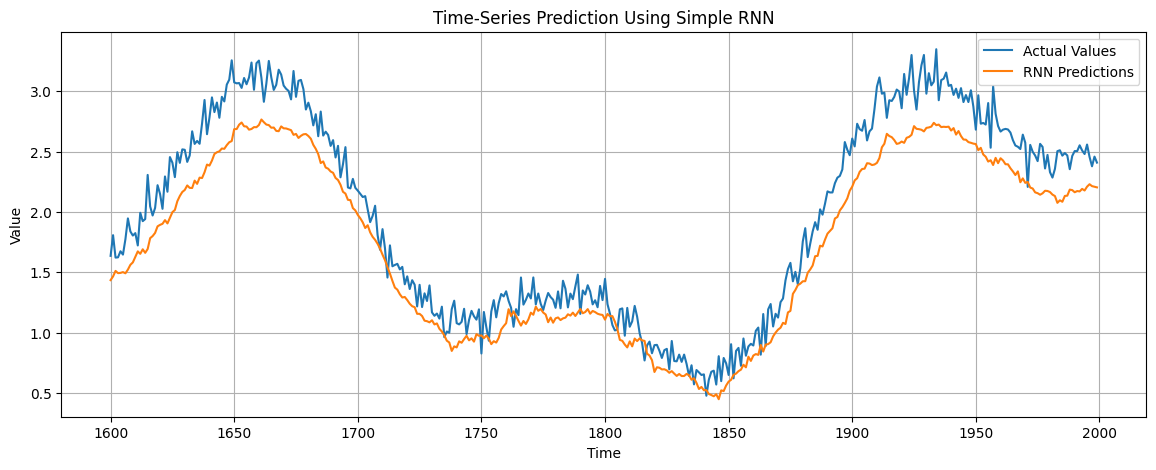

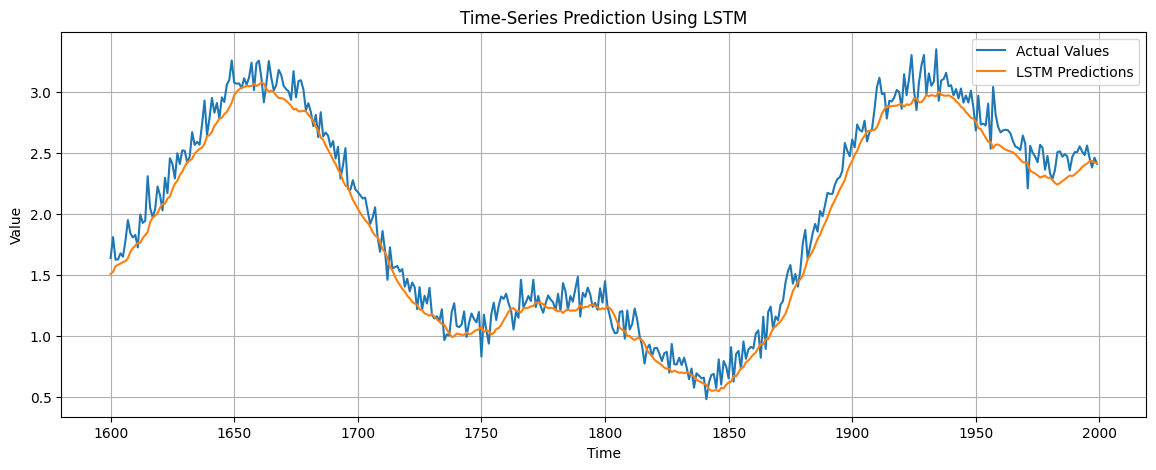

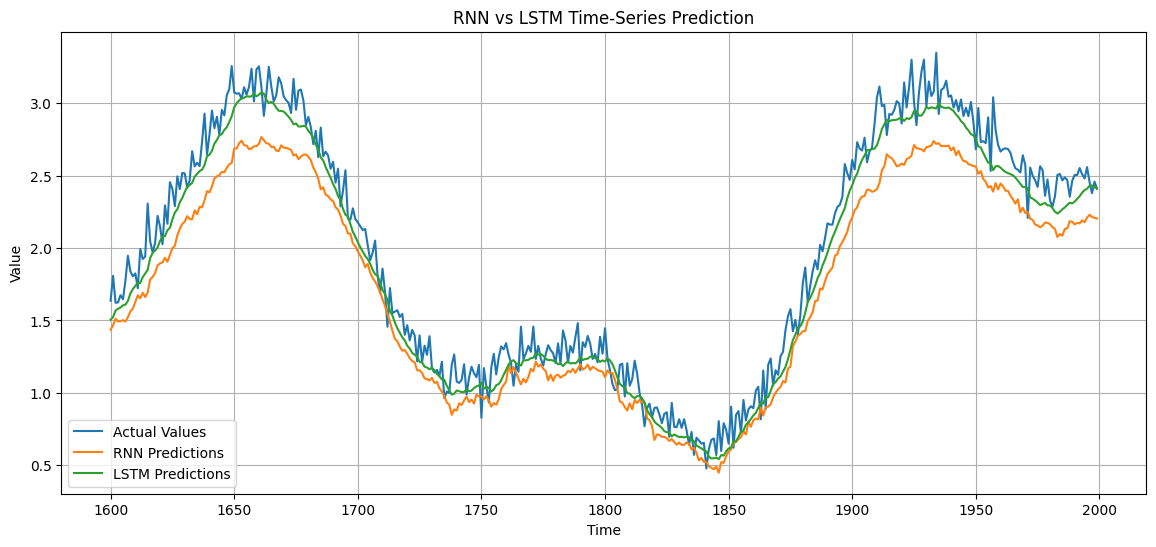


MODEL PERFORMANCE COMPARISON
       Model       MSE       MAE      RMSE
0  SimpleRNN  0.082795  0.251974  0.287741
1       LSTM  0.022596  0.122483  0.150320


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout, Input

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate Synthetic Time-Series Data

time = np.arange(0, 2000)

data = (
    np.sin(0.02 * time) +
    0.5 * np.sin(0.05 * time) +
    0.001 * time +
    np.random.normal(0, 0.1, len(time))
)

df = pd.DataFrame({
    "Time": time,
    "Value": data
})

print(df.head())
print("Dataset Shape:", df.shape)

# 2. Visualize Original Time-Series Data

plt.figure(figsize=(14, 5))

plt.plot(df["Time"], df["Value"])

plt.title("Synthetic Time-Series Data")
plt.xlabel("Time")
plt.ylabel("Value")

plt.grid()
plt.show()

# 3. Normalize Data

scaler = MinMaxScaler(feature_range=(0, 1))

train_size = int(len(data) * 0.8)

scaler.fit(data[:train_size].reshape(-1, 1))

scaled_data = scaler.transform(
    data.reshape(-1, 1)
)

print("Scaled Data Shape:", scaled_data.shape)

# 4. Create Sequences

time_steps = 50

def create_sequences(data, time_steps):

    X = []
    y = []

    for i in range(time_steps, len(data)):

        X.append(data[i-time_steps:i, 0])

        y.append(data[i, 0])

    return np.array(X), np.array(y)


X, y = create_sequences(
    scaled_data,
    time_steps
)

X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

# Split Chronologically

target_indices = np.arange(time_steps, len(data))

train_mask = target_indices < train_size
test_mask = target_indices >= train_size

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("X Train:", X_train.shape)
print("y Train:", y_train.shape)

print("X Test:", X_test.shape)
print("y Test:", y_test.shape)

# 5. Build Simple RNN Model

rnn_model = Sequential([

    Input(shape=(time_steps, 1)),

    SimpleRNN(50, activation="tanh"),

    Dropout(0.2),

    Dense(25, activation="relu"),

    Dense(1)

])

rnn_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

rnn_model.summary()

# 6. Train RNN Model

rnn_history = rnn_model.fit(

    X_train,
    y_train,

    epochs=20,

    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    verbose=1

)

# 7. Build LSTM Model

lstm_model = Sequential([

    Input(shape=(time_steps, 1)),

    LSTM(50, activation="tanh"),

    Dropout(0.2),

    Dense(25, activation="relu"),

    Dense(1)

])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

lstm_model.summary()

# 8. Train LSTM Model

lstm_history = lstm_model.fit(

    X_train,
    y_train,

    epochs=20,

    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    verbose=1

)

# 9. Make Predictions Using RNN

rnn_predictions = rnn_model.predict(X_test)

rnn_predictions = scaler.inverse_transform(
    rnn_predictions
)

# 10. Make Predictions Using LSTM

lstm_predictions = lstm_model.predict(X_test)

lstm_predictions = scaler.inverse_transform(
    lstm_predictions
)

# Convert Actual Values Back to Original Scale

actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# 11. Plot Actual vs RNN Predictions

test_time = target_indices[test_mask]

plt.figure(figsize=(14, 5))

plt.plot(
    test_time,
    actual_values,
    label="Actual Values"
)

plt.plot(
    test_time,
    rnn_predictions,
    label="RNN Predictions"
)

plt.title("Time-Series Prediction Using Simple RNN")

plt.xlabel("Time")
plt.ylabel("Value")

plt.legend()
plt.grid()
plt.show()

# 12. Plot Actual vs LSTM Predictions

plt.figure(figsize=(14, 5))

plt.plot(
    test_time,
    actual_values,
    label="Actual Values"
)

plt.plot(
    test_time,
    lstm_predictions,
    label="LSTM Predictions"
)

plt.title("Time-Series Prediction Using LSTM")

plt.xlabel("Time")
plt.ylabel("Value")

plt.legend()
plt.grid()
plt.show()

# 13. Compare RNN and LSTM Predictions

plt.figure(figsize=(14, 6))

plt.plot(
    test_time,
    actual_values,
    label="Actual Values"
)

plt.plot(
    test_time,
    rnn_predictions,
    label="RNN Predictions"
)

plt.plot(
    test_time,
    lstm_predictions,
    label="LSTM Predictions"
)

plt.title("RNN vs LSTM Time-Series Prediction")

plt.xlabel("Time")
plt.ylabel("Value")

plt.legend()
plt.grid()
plt.show()

# 14. Evaluate RNN Model

rnn_mse = mean_squared_error(
    actual_values,
    rnn_predictions
)

rnn_mae = mean_absolute_error(
    actual_values,
    rnn_predictions
)

rnn_rmse = np.sqrt(rnn_mse)

# 15. Evaluate LSTM Model

lstm_mse = mean_squared_error(
    actual_values,
    lstm_predictions
)

lstm_mae = mean_absolute_error(
    actual_values,
    lstm_predictions
)

lstm_rmse = np.sqrt(lstm_mse)

# 16. Display Model Comparison

results = pd.DataFrame({

    "Model": ["SimpleRNN", "LSTM"],

    "MSE": [rnn_mse, lstm_mse],

    "MAE": [rnn_mae, lstm_mae],

    "RMSE": [rnn_rmse, lstm_rmse]

})

print("\nMODEL PERFORMANCE COMPARISON")

print(results)


# Sequence pattern classification
**Objective:** Train a neural network to recognize patterns in sequential data.

Real-world example: Imagine a system monitoring daily temperatures. It learns whether temperatures are increasing, decreasing, or fluctuating.

We will generate synthetic sequences and classify them into three categories:
- Class 0: Increasing sequence.
- Class 1: Decreasing sequence.
- Class 2: Oscillating sequence.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, accuracy_score

np.random.seed(42)
tf.random.set_seed(42)

**Generate synthetic sequential data**

Input shape: (1500, 50, 1)
Labels shape: (1500,)


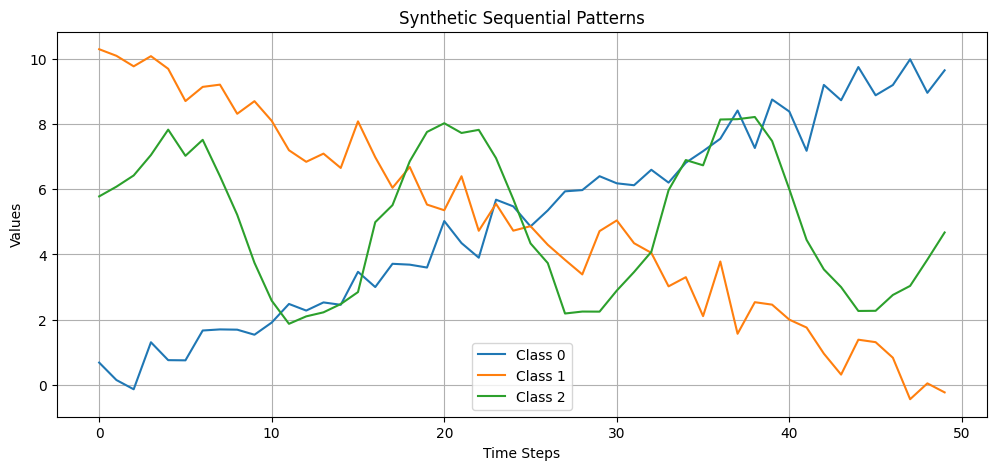

Training data: (1200, 50, 1)
Testing data: (300, 50, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,075 (74.51 KB)

 Trainable params: 19,075 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.8558 - loss: 0.5176 - val_accuracy: 1.0000 - val_loss: 0.0514
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 1.0000 - loss: 0.0144 - val_accuracy: 1.0000 - val_loss: 0.0037
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 8.5495e-04
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 1.0000 - loss: 7.4904e-04 - val_accuracy: 1.0000 - val_loss: 6.4402e-04
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 1.0000 - loss: 5.7443e-04 - val_accuracy: 1.0000 - val_loss: 5.0433e-04
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 1.0000 - loss: 4.5617e-04 - 

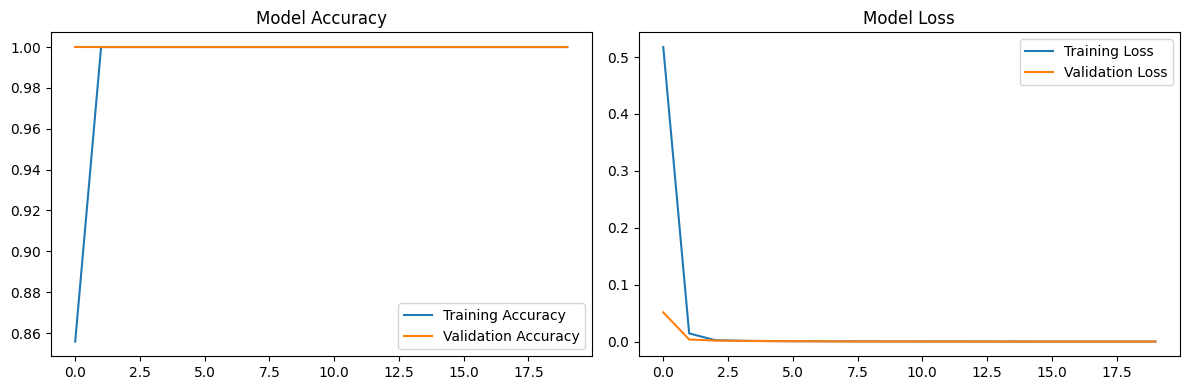

In [ ]:
def generate_sequence(pattern, length=50):
    x = np.linspace(0, 1, length)

    if pattern == 0:
        sequence = x * 10

    elif pattern == 1:
        sequence = 10 - (x * 10)

    else:
        sequence = 5 + 3 * np.sin(2 * np.pi * 3 * x)

    noise = np.random.normal(0, 0.5, length)

    return sequence + noise

X = []
y = []

for label in range(3):
    for i in range(500):
        X.append(generate_sequence(label))
        y.append(label)

X = np.array(X)
y = np.array(y)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("Input shape:", X.shape)
print("Labels shape:", y.shape)
#visualization
plt.figure(figsize=(12, 5))

for i in range(3):
    plt.plot(X[i * 500][ :, 0], label=f"Class {i}")

plt.title("Synthetic Sequential Patterns")
plt.xlabel("Time Steps")
plt.ylabel("Values")
plt.legend()
plt.grid()
plt.show()

#split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
#Build LSTM Classificaion model
model = Sequential([
    Input(shape=(50, 1)),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#train  model
model.summary()
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test)
)
#Evaluate
predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    target_names=["Increasing", "Decreasing", "Oscillating"]
))
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

**Exercise 2: Visualize hidden states**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
Sequence Output: (1, 50, 32)
Hidden State: (1, 32)
Cell State: (1, 32)


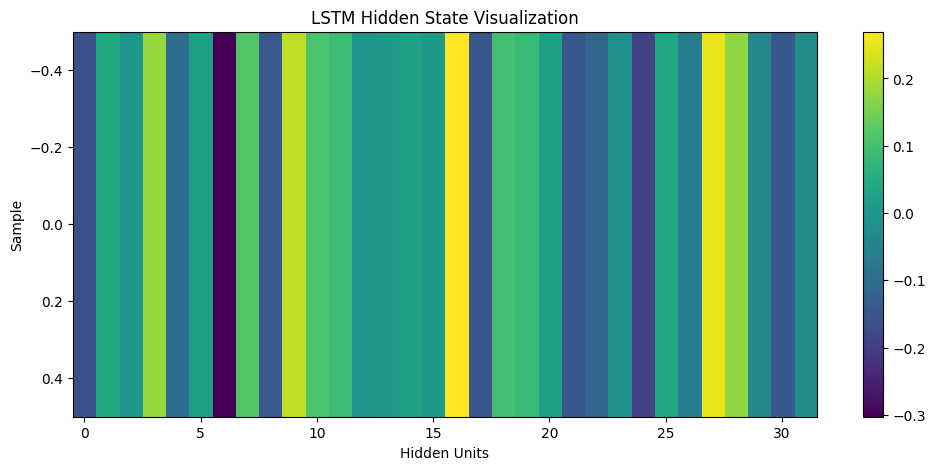

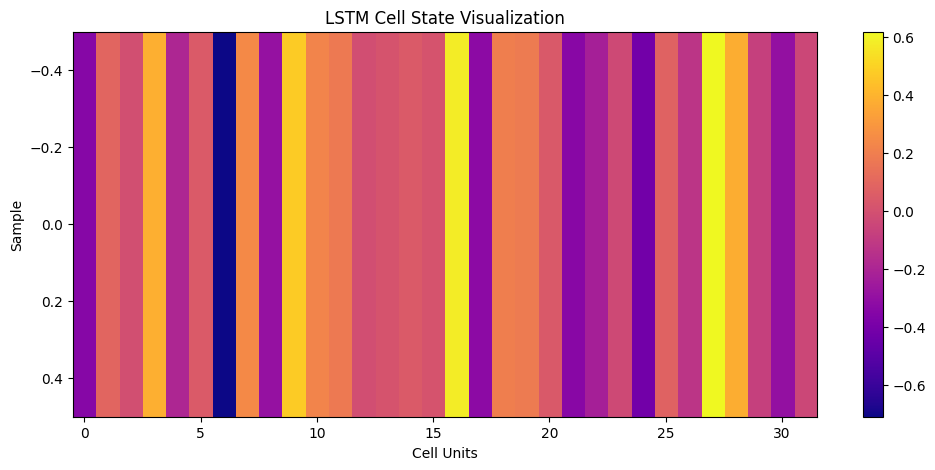

In [ ]:
#Create an LSTM model that returns hidden states
inputs = Input(shape=(50, 1))

lstm_layer = LSTM(32, return_sequences=True, return_state=True)

sequence_output, hidden_state, cell_state = lstm_layer(inputs)

hidden_model = Model(inputs, [
    sequence_output,
    hidden_state,
    cell_state
])

#Extract hidden and cell states
sample = X_test[:1]

sequence_output, hidden_state, cell_state = hidden_model.predict(sample)

print("Sequence Output:", sequence_output.shape)
print("Hidden State:", hidden_state.shape)
print("Cell State:", cell_state.shape)

#Visualize hidden states
plt.figure(figsize=(12, 5))

plt.imshow(hidden_state, cmap='viridis', aspect='auto')

plt.title("LSTM Hidden State Visualization")
plt.xlabel("Hidden Units")
plt.ylabel("Sample")

plt.colorbar()
plt.show()
#Visualize cell states
plt.figure(figsize=(12, 5))

plt.imshow(cell_state, cmap='plasma', aspect='auto')

plt.title("LSTM Cell State Visualization")
plt.xlabel("Cell Units")
plt.ylabel("Sample")

plt.colorbar()
plt.show()